# Intent dataset

Every chat message first goes through the intent classifier, which decides where the message should go. This notebook looks at the data we train it on.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../../data/intent_dataset.csv")
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (2008, 4)


,text,intent,dialect,source
0,اعمل ميزانية ازاي بمرتب 12 ألف,advice,ar-eg,generated
1,احوش ازاي لجهاز العروسة,advice,ar-eg,generated
2,اسدد القرض الاول ولا احوش,advice,ar-eg,generated
3,اشتري دهب ولا احوش,advice,ar-eg,generated
4,المفروض مصاريف الأكل متزيدش عن كام في المية من...,advice,ar-eg,generated


In [2]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate texts:", df["text"].duplicated().sum())

Missing values:
text       0
intent     0
dialect    0
source     0
dtype: int64

Duplicate texts: 0


### Intents

- **transaction**: logging an expense or income ("اشتريت لاب ب 5000")
- **spending_query**: questions about my own spending ("صرفت كام على الأكل الشهر ده؟")
- **forecast**: predictions ("هصرف كام الشهر الجاي؟")
- **market**: prices, stocks, gold, exchange rates ("الدولار بكام؟")
- **advice**: saving and budgeting tips ("احوش ازاي من مرتبي؟")
- **manage**: delete or edit something already saved ("امسح آخر حاجة")
- **greeting**, **out_of_scope**

intent
transaction       560
spending_query    279
advice            224
market            223
manage            211
out_of_scope      200
greeting          158
forecast          153
Name: count, dtype: int64


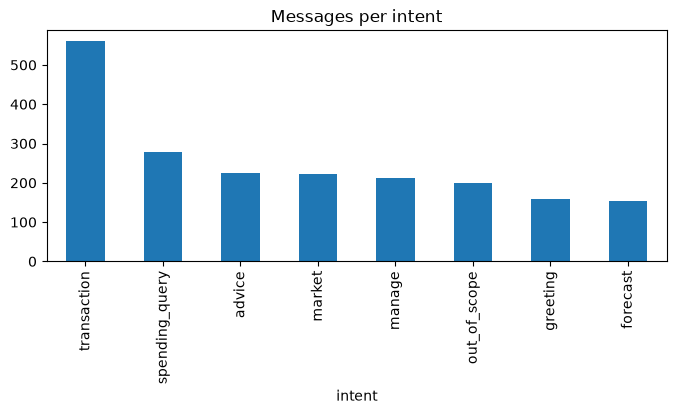

In [3]:
counts = df["intent"].value_counts()
print(counts)

counts.plot(kind="bar", figsize=(8, 3), title="Messages per intent")
plt.show()

transaction is capped at 500 on purpose. We have ~1,700 transaction messages, and using all of them would drown the other intents.

In [4]:
pd.crosstab(df["intent"], df["dialect"])

dialect,ar-eg,en,franco,mixed
intent,,,,
advice,136,22,34,32
forecast,92,16,23,22
greeting,94,16,25,23
manage,126,22,32,31
market,134,22,33,34
out_of_scope,115,28,27,30
spending_query,165,29,42,43
transaction,334,74,82,70


In [5]:
pd.crosstab(df["intent"], df["source"])

source,generated,relabeled,transaction_set
intent,,,
advice,200,24,0
forecast,150,3,0
greeting,100,13,45
manage,150,61,0
market,220,3,0
out_of_scope,150,50,0
spending_query,200,79,0
transaction,60,0,500


`generated` = new messages written for this classifier, `relabeled` = old questions and corrections from the transaction dataset that we labeled again by intent, `transaction_set` = taken directly from the transaction dataset.

In [6]:
for intent in counts.index:
    print(f"--- {intent}")
    for text in df[df["intent"] == intent]["text"].sample(3, random_state=1):
        print("  ", text)

--- transaction
   gebt khodar w fakha men Seoudi b 340 EGP
   عباية سوداء لماما من عباس العقاد ب 1300 جنيه
   saraft 1150 egp el naharda el sob7 3nd Fawry
--- spending_query
   هي مصاريف العربية الشهر ده عدت ال 3000 جنيه؟
   هو انا عديت ال limit بتاع ميزانية الكافيهات ولا لسه؟
   صرفت كام على ال food delivery الأسبوع ده؟
--- advice
   لو عليا ديون لأشخاص وأقساط لبنوك أرتب أولوية السداد ازاي؟
   ايه الغلطات اللي بتخلي الواحد يقع في فخ فوائد فيزا المشتريات؟
   امتى يكون كسر شهادة البنك عشان أشتري أصل أو أسدد دين قرار صح؟
--- market
   سهم الإسكندرية لتداول الحاويات بيوزع أرباح بالدولار ولا بالجنيه وسعره كام؟
   الدينار الكويتي عامل كام جنيه في البنك الأهلي النهارده؟
   سهم بلتون القابضة حجم التداول عليه كام مليون جنيه النهاردة؟
--- manage
   قسم ال 1000 اللي فاتت نصين 500 اكل و 500 شوبينج
   Cancel the last InstaPay transfer entry, it failed
   امسح اللي كتبته ده كيبورد الموبايل خرف
--- out_of_scope
   تمرين البنش بريس بيشغل عضلة ايه غير الصدر؟
   ازاي اصلح زرار الباور في دراع البلايستي

In [7]:
df["words"] = df["text"].str.split().str.len()
df.groupby("intent")["words"].describe()[["mean", "min", "max"]].round(1)

,mean,min,max
intent,,,
advice,11.0,4.0,20.0
forecast,11.6,4.0,20.0
greeting,5.1,1.0,12.0
manage,8.4,1.0,13.0
market,9.8,2.0,16.0
out_of_scope,9.6,3.0,21.0
spending_query,8.7,4.0,15.0
transaction,8.4,2.0,21.0
